# Market-Risk VaR Engine — Day 1
## Portfolio, Data, and the P&L Series

This notebook sets up the foundation of a multi-asset market-risk engine:
a realistic trading book, its market data, and the **daily P&L series** that
every downstream risk measure (VaR, Expected Shortfall, backtesting, PLAT)
will operate on.

**Why a multi-asset book?** The whole purpose of portfolio VaR is to capture
how correlation and diversification shape *total* risk. A single-asset book
would miss that. So we build a small but genuine mix of equities, FX, and
rates — with both long and short positions, so the risk has real structure.


In [1]:
import numpy as np
import pandas as pd

try:
    import yfinance as yf

    HAVE_YF = True
except ImportError:
    HAVE_YF = False

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. The portfolio

Each position has a **signed USD notional** — the dollar exposure times its
direction (+1 long, -1 short). The book deliberately mixes longs and shorts:

- **Equities:** long AAPL and JPM, **short** SPY (a hedge against the equity longs)
- **FX:** long EUR (FXE), short JPY (FXY)
- **Rates:** long long-dated Treasuries (TLT)

The short SPY position is what makes this interesting: it offsets the equity
longs, so the *covariance structure* between instruments actually matters —
which is exactly what portfolio VaR is designed to measure.


In [2]:
PORTFOLIO = {
    "AAPL": (1_000_000, +1),
    "JPM": (750_000, +1),
    "SPY": (2_000_000, -1),
    "FXE": (1_500_000, +1),
    "FXY": (1_000_000, -1),
    "TLT": (1_250_000, +1),
}

START_DATE = "2019-01-01"
END_DATE = "2024-12-31"


def signed_notionals():
    """Signed USD exposure per instrument (notional * direction)."""
    return pd.Series({t: n * d for t, (n, d) in PORTFOLIO.items()})


w = signed_notionals()
print("Signed USD exposure per instrument:")
for t, v in w.items():
    print(f"  {t:>5}: {v:>+14,.0f}")
print(f"\n  Gross exposure: {w.abs().sum():>14,.0f}")
print(f"  Net exposure:   {w.sum():>+14,.0f}")

Signed USD exposure per instrument:
   AAPL:     +1,000,000
    JPM:       +750,000
    SPY:     -2,000,000
    FXE:     +1,500,000
    FXY:     -1,000,000
    TLT:     +1,250,000

  Gross exposure:      7,500,000
  Net exposure:       +1,500,000


Notice the **gross exposure** (sum of absolute positions) is far larger than
the **net exposure** (sum of signed positions). That gap is the offsetting
long/short structure — the diversification that VaR will quantify. A naive
"sum of individual risks" would massively overstate the true portfolio risk.


## 2. Market data

We pull daily prices from Yahoo Finance. **If the download is unavailable**
(no internet, or a blocked host), the notebook falls back to realistic
**synthetic** prices so everything still runs end-to-end. On your own machine
with internet, it will use the real data automatically.

The FX exposures use **FXE** (Euro ETF) and **FXY** (Yen ETF) rather than raw
FX tickers — they behave like ordinary equities and load reliably.


In [3]:
def download_real_prices():
    tickers = list(PORTFOLIO.keys())
    raw = yf.download(
        tickers, start=START_DATE, end=END_DATE, auto_adjust=True, progress=False
    )["Close"]
    return raw[tickers].dropna()


def make_synthetic_prices():
    "Realistic correlated daily prices as a fallback."
    dates = pd.bdate_range(START_DATE, END_DATE)
    n = len(dates)
    tickers = list(PORTFOLIO.keys())

    ann_vol = {
        "AAPL": 0.30,
        "JPM": 0.28,
        "SPY": 0.18,
        "FXE": 0.08,
        "FXY": 0.10,
        "TLT": 0.13,
    }
    daily_vol = {t: v / np.sqrt(252) for t, v in ann_vol.items()}

    beta = {"AAPL": 1.1, "JPM": 1.0, "SPY": 1.0, "FXE": 0.1, "FXY": -0.1, "TLT": -0.3}
    market = np.random.normal(0, 0.01, n)

    rets = {}
    for t in tickers:
        idio = np.random.normal(0, daily_vol[t], n)
        rets[t] = beta[t] * market + idio
    rets = pd.DataFrame(rets, index=dates)

    prices = 100 * np.exp(rets.cumsum())
    return prices


if HAVE_YF:
    try:
        prices = download_real_prices()
        if prices.empty:
            raise RuntimeError("empty download")
        SOURCE = "real (Yahoo Finance)"
    except Exception as e:
        prices = make_synthetic_prices()
        SOURCE = f"synthetic (download failed: {type(e).__name__})"
else:
    prices = make_synthetic_prices()
    SOURCE = "synthetic (yfinance not installed)"

print(f"Data source: {SOURCE}")
print(f"Loaded {prices.shape[0]} days x {prices.shape[1]} instruments")
print(f"Range: {prices.index.min().date()} to {prices.index.max().date()}")
prices.head()

Data source: real (Yahoo Finance)
Loaded 1509 days x 6 instruments
Range: 2019-01-02 to 2024-12-30


Ticker,AAPL,JPM,SPY,FXE,FXY,TLT
Date,,,,,,
2019-01-02,37.4085,80.0745,223.2516,102.6463,87.6500,96.7618
2019-01-03,33.6823,78.9365,217.9242,103.0912,88.8200,97.8630
2019-01-04,35.1202,81.8465,225.2237,103.1101,88.0500,96.7302
2019-01-07,35.0420,81.9034,226.9995,103.7917,87.8500,96.4450
2019-01-08,35.7100,81.7490,229.1323,103.4698,87.8000,96.1915


## 3. Returns and the portfolio P&L

We use **log returns** (additive over time, roughly symmetric — the convention
in risk modeling). Then the daily portfolio P&L is, for each day, the sum over
positions of `signed_notional * instrument_return`.

This is the standard **linear approximation**: a position of \$N in an asset
that moves by return *r* makes \$N·r. For a daily horizon and linear
instruments (stocks, FX, ETFs) it's exact enough. It breaks down for options
(non-linear payoffs) — a limitation we'll record in the model documentation.


In [4]:
def compute_returns(prices):
    """Daily log returns."""
    return np.log(prices / prices.shift(1)).dropna()


def portfolio_pnl(returns, w):
    """Daily P&L of the whole book in USD."""
    aligned = returns[w.index]
    return pd.Series(aligned.values @ w.values, index=aligned.index, name="pnl")


returns = compute_returns(prices)
pnl = portfolio_pnl(returns, w)

print("Daily P&L (USD) summary:")
print(f"  Observations:    {len(pnl):>12,d}")
print(f"  Mean:            {pnl.mean():>+12,.0f}")
print(f"  Std dev:         {pnl.std():>12,.0f}")
print(f"  Worst day:       {pnl.min():>+12,.0f}")
print(f"  Best day:        {pnl.max():>+12,.0f}")
print(f"  5th percentile:  {pnl.quantile(0.05):>+12,.0f}")
print(f"  1st percentile:  {pnl.quantile(0.01):>+12,.0f}")

Daily P&L (USD) summary:
  Observations:           1,508
  Mean:                    +558
  Std dev:               17,871
  Worst day:           -109,981
  Best day:             +99,836
  5th percentile:       -27,709
  1st percentile:       -42,438


### The percentiles are a preview of VaR

Look at the **1st and 5th percentiles** of the daily P&L. Those are, in
essence, what VaR formalizes: *"the loss we expect to exceed only 1% (or 5%)
of the time."* The 1-day 99% VaR is essentially the negative of that 1st
percentile. Tomorrow (Day 2) we compute this three different ways — historical,
parametric, and Monte Carlo — and add Expected Shortfall.


In [5]:
corr = returns.corr()
print("Return correlation matrix:")
corr

Return correlation matrix:


Ticker,AAPL,JPM,SPY,FXE,FXY,TLT
Ticker,,,,,,
AAPL,1.0000,0.4166,0.7845,0.1583,-0.0846,-0.1106
JPM,0.4166,1.0000,0.7099,0.1311,-0.2183,-0.3028
SPY,0.7845,0.7099,1.0000,0.2095,-0.1178,-0.1706
FXE,0.1583,0.1311,0.2095,1.0000,0.4537,0.1752
FXY,-0.0846,-0.2183,-0.1178,0.4537,1.0000,0.4160
TLT,-0.1106,-0.3028,-0.1706,0.1752,0.4160,1.0000


The correlation matrix is the engine of portfolio risk. The equities
(AAPL, JPM, SPY) are positively correlated, so the **short** SPY position
offsets much of the long equity risk. FX and rates are more weakly correlated
with equities, adding genuine diversification. Parametric VaR (Day 2) uses
this matrix directly; historical and Monte Carlo VaR capture the same
structure implicitly.


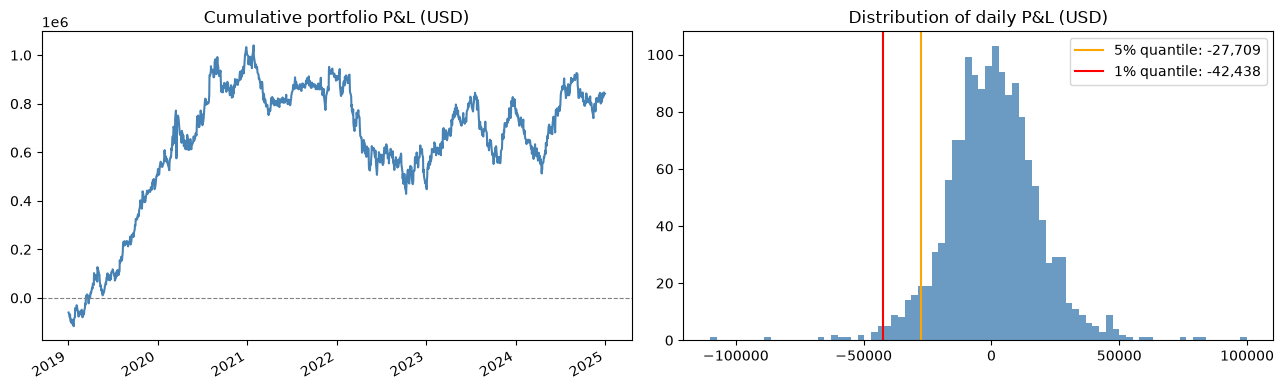

In [6]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))


pnl.cumsum().plot(ax=ax1, color="steelblue")
ax1.set_title("Cumulative portfolio P&L (USD)")
ax1.set_xlabel("")
ax1.axhline(0, color="grey", lw=0.8, ls="--")


ax2.hist(pnl, bins=80, color="steelblue", alpha=0.8)
for q, c, label in [(0.05, "orange", "5% quantile"), (0.01, "red", "1% quantile")]:
    x = pnl.quantile(q)
    ax2.axvline(x, color=c, lw=1.5, label=f"{label}: {x:,.0f}")
ax2.set_title("Distribution of daily P&L (USD)")
ax2.legend()
plt.tight_layout()
plt.show()

## Day 1 summary

We built:

1. A **multi-asset book** (equities + FX + rates) with deliberate long/short
   structure, so correlation and diversification matter.
2. A reproducible **data layer** (real Yahoo data, synthetic fallback).
3. The **daily P&L series** — the single object every risk measure runs on.

The percentiles of that P&L already preview the VaR we'll formalize next.

**Day 2:** the three VaR methods — historical simulation, parametric
(variance-covariance), and Monte Carlo — plus Expected Shortfall, the FRTB
successor to VaR.
